# 2  Processing Real-World Multi-Axis Sensor Data with N-Dimensional Wavelet Transforms

## 2.5 PyWavelets Implementation

### 2.5.1 Complete Implementation Example

Loading synthetic seismic data...
Synthetic data loaded successfully!
Applying Gaussian denoising...
Normalizing data...
Preprocessing complete. Shape: (200, 150, 100)
Performing Mallat decomposition (level=3)...
Total coefficient energy: 7.39e+06
Figure saved to ./output\wavelet_results_Mallat.png


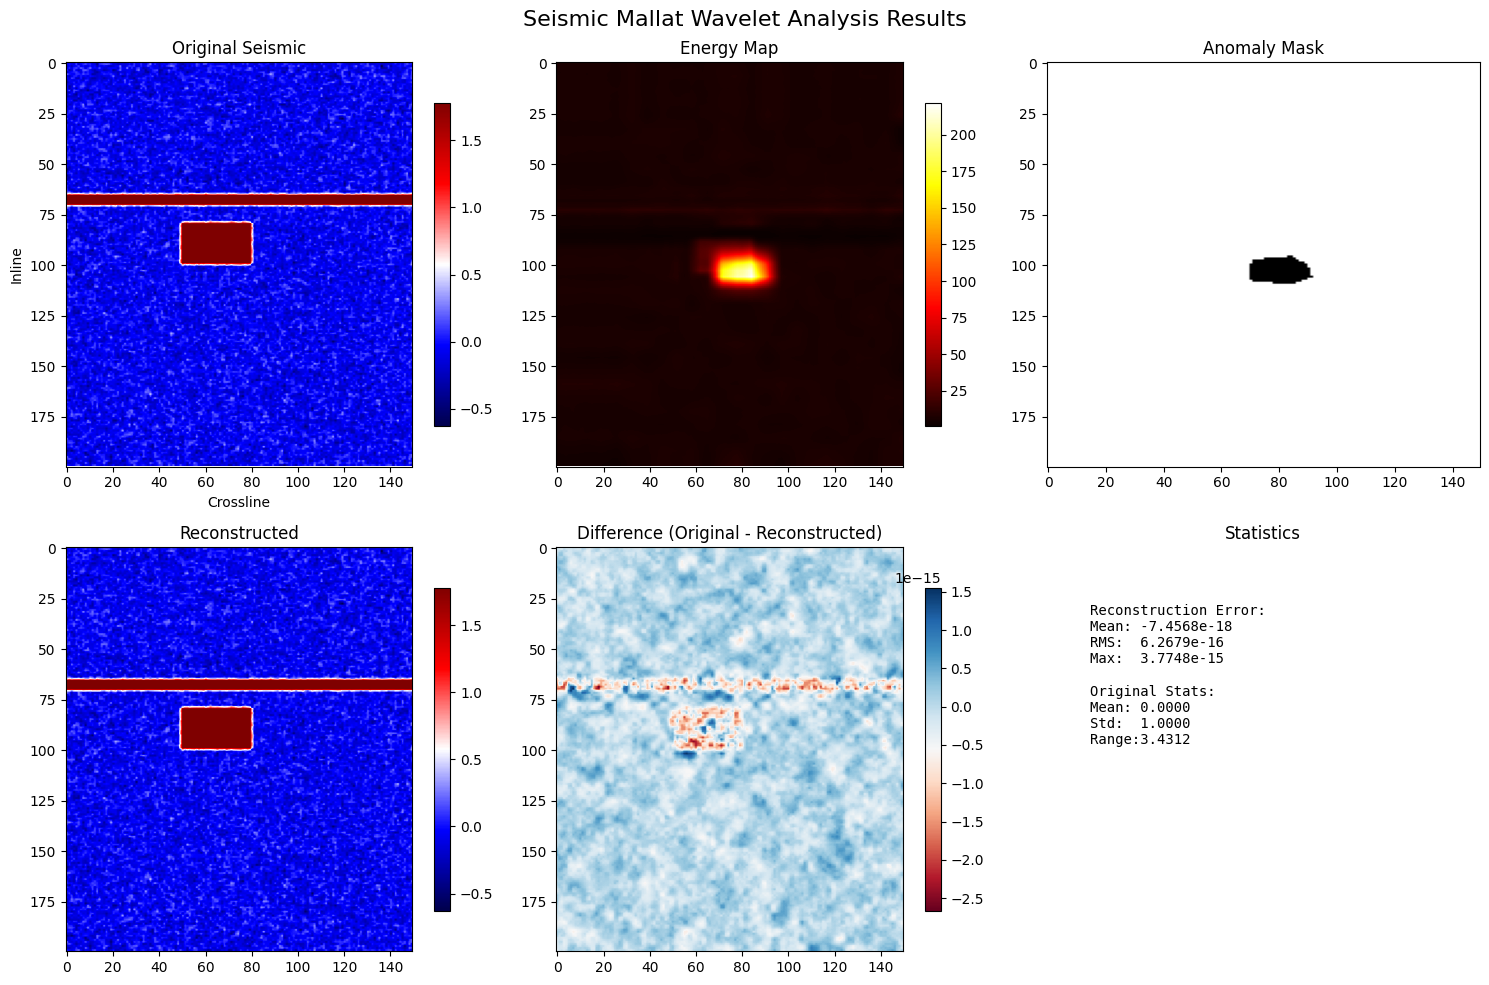


Trying fully separable decomposition...
Performing separable decomposition (level=(3, 3, 2))...
Total coefficient energy: 6.07e+06
Figure saved to ./output\wavelet_results_Separable.png


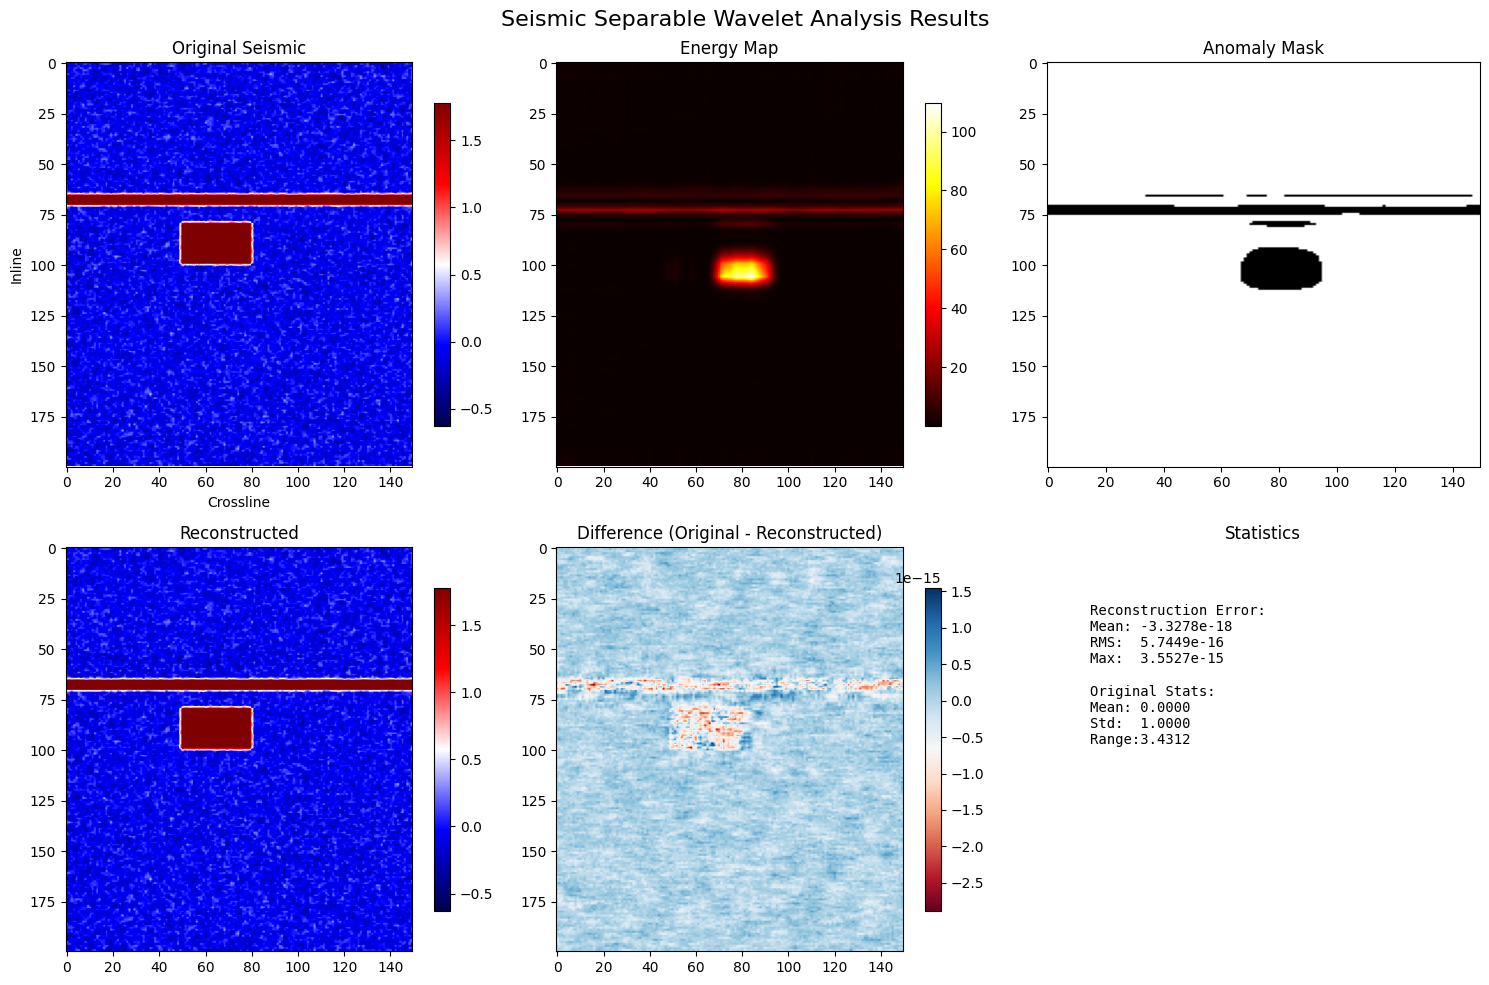

In [53]:
import pywt
import numpy as np
import requests
import io
import matplotlib.pyplot as plt
from scipy import ndimage
import os
from datetime import datetime

class SeismicWaveletProcessor:
    """
    Comprehensive processor for seismic data using n-dimensional wavelets
    """

    def __init__(self, wavelet='db4', mode='symmetric'):
        self.wavelet = wavelet
        self.mode = mode
        self.volume = None
        self.coeffs = None
        self.stats = {}
        self.has_fswavedecn = hasattr(pywt, 'fswavedecn')

    # ------------------------------------------------------------------
    # I/O
    # ------------------------------------------------------------------
    def load_data(self, url=None, local_path=None):
        if url:
            print("Downloading seismic data...")
            resp = requests.get(url, stream=True)
            if resp.status_code == 200:
                self.volume = np.load(io.BytesIO(resp.content))
            else:
                raise ValueError(f"Failed to download data: {resp.status_code}")
        elif local_path:
            self.volume = np.load(local_path)
        else:
            raise ValueError("Either URL or local_path must be provided")
        print(f"Loaded volume shape: {self.volume.shape}")
        self._compute_statistics()

    # ------------------------------------------------------------------
    # statistics
    # ------------------------------------------------------------------
    def _compute_statistics(self):
        self.stats = {
            'mean': np.mean(self.volume),
            'std': np.std(self.volume),
            'min': np.min(self.volume),
            'max': np.max(self.volume),
            'dynamic_range': np.max(self.volume) - np.min(self.volume),
            'rms': np.sqrt(np.mean(self.volume ** 2))
        }

    # ------------------------------------------------------------------
    # preprocessing
    # ------------------------------------------------------------------
    def preprocess(self, normalize=True, denoise=False, sigma=1.0):
        if self.volume is None:
            raise ValueError("No data loaded")

        if denoise:
            print("Applying Gaussian denoising...")
            self.volume = ndimage.gaussian_filter(self.volume, sigma=sigma)

        if normalize:
            print("Normalizing data...")
            p5, p95 = np.percentile(self.volume, [5, 95])
            self.volume = np.clip(self.volume, p5, p95)
            self.volume = (self.volume - np.mean(self.volume)) / np.std(self.volume)

        print(f"Preprocessing complete. Shape: {self.volume.shape}")
        self._compute_statistics()

    # ------------------------------------------------------------------
    # decomposition
    # ------------------------------------------------------------------
    def decompose_mallat(self, level=2):
        print(f"Performing Mallat decomposition (level={level})...")
        self.coeffs = pywt.wavedecn(self.volume, wavelet=self.wavelet, level=level, mode=self.mode)
        self._analyze_coefficients()
        return self.coeffs

    def decompose_separable(self, level):
        if not self.has_fswavedecn:
            print("pywt.fswavedecn not available. Skipping separable decomposition.")
            return None
        print(f"Performing separable decomposition (level={level})...")
        self.coeffs = pywt.fswavedecn(self.volume, wavelet=self.wavelet, levels=level, mode=self.mode)
        self._analyze_coefficients()
        return self.coeffs

    # ------------------------------------------------------------------
    # coefficient analysis
    # ------------------------------------------------------------------
    def _analyze_coefficients(self):
        total_energy = 0
        if self.has_fswavedecn and isinstance(self.coeffs, pywt.FswavedecnResult):
            total_energy += np.sum(self.coeffs.approx ** 2)
            for key in self.coeffs.detail_keys():
                total_energy += np.sum(self.coeffs[key] ** 2)
        else:
            total_energy += np.sum(self.coeffs[0] ** 2)
            for level_coeffs in self.coeffs[1:]:
                for subband in level_coeffs.values():
                    total_energy += np.sum(subband ** 2)
        print(f"Total coefficient energy: {total_energy:.2e}")

    # ------------------------------------------------------------------
    # anomaly detection
    # ------------------------------------------------------------------
    def detect_anomalies(self, threshold_percentile=85, method='energy'):
        if self.coeffs is None:
            raise ValueError("No decomposition available.")

        if method == 'energy':
            return self._energy_based_detection(threshold_percentile)
        elif method == 'statistical':
            return self._statistical_detection(threshold_percentile)
        else:
            raise ValueError("Method must be 'energy' or 'statistical'")

    def _energy_based_detection(self, threshold_percentile):
        energy_map = np.zeros_like(self.volume)
        if self.has_fswavedecn and isinstance(self.coeffs, pywt.FswavedecnResult):
            for key in self.coeffs.detail_keys():
                subband = self.coeffs[key]
                resized = self._resize_to_volume(subband)
                energy_map += resized ** 2
        else:
            for level_coeffs in self.coeffs[1:]:
                for subband in level_coeffs.values():
                    resized = self._resize_to_volume(subband)
                    energy_map += resized ** 2

        threshold = np.percentile(energy_map, threshold_percentile)
        anomaly_mask = energy_map > threshold
        return anomaly_mask, energy_map

    def _statistical_detection(self, threshold_percentile):
        all_details = []
        if self.has_fswavedecn and isinstance(self.coeffs, pywt.FswavedecnResult):
            for key in self.coeffs.detail_keys():
                all_details.extend(self.coeffs[key].flatten())
        else:
            for level_coeffs in self.coeffs[1:]:
                for subband in level_coeffs.values():
                    all_details.extend(subband.flatten())
        all_details = np.array(all_details)
        threshold = np.percentile(np.abs(all_details), threshold_percentile)

        anomaly_mask = np.zeros_like(self.volume, dtype=bool)
        for level_coeffs in self.coeffs[1:]:
            for subkey, subband in level_coeffs.items():
                level_coeffs[subkey] = np.where(np.abs(subband) > threshold, subband, 0)
                resized_mask = self._resize_to_volume(np.abs(subband) > 0)
                anomaly_mask = np.logical_or(anomaly_mask, resized_mask)

        return anomaly_mask, threshold

    def _resize_to_volume(self, subband):
        if subband.shape == self.volume.shape:
            return subband
        zoom_factors = [s1 / s2 for s1, s2 in zip(self.volume.shape, subband.shape)]
        return ndimage.zoom(subband, zoom_factors, order=1)

    # ------------------------------------------------------------------
    # reconstruction
    # ------------------------------------------------------------------
    def reconstruct(self):
        if self.coeffs is None:
            raise ValueError("No coefficients available")
        if self.has_fswavedecn and isinstance(self.coeffs, pywt.FswavedecnResult):
            return pywt.fswaverecn(self.coeffs)
        else:
            return pywt.waverecn(self.coeffs, wavelet=self.wavelet, mode=self.mode)
        
    # ------------------------------------------------------------------
    # energy map computation
    # ------------------------------------------------------------------
        
    def compute_energy_map(self):
        """
        Compute energy map (sum of squared wavelet detail coefficients).
        """
        energy_map = np.zeros_like(self.volume)

        if self.has_fswavedecn and isinstance(self.coeffs, pywt.FswavedecnResult):
            # For fully separable decomposition
            for key in self.coeffs.detail_keys():
                subband = self.coeffs[key]
                resized = self._resize_to_volume(subband)
                energy_map += resized ** 2
        else:
            # For Mallat decomposition
            for level_coeffs in self.coeffs[1:]:
                for arr in level_coeffs.values():
                    resized = self._resize_to_volume(arr)
                    energy_map += resized ** 2

        return energy_map

    # ------------------------------------------------------------------
    # visualization
    # ------------------------------------------------------------------
    def visualize_results(self, slice_idx=None, figsize=(15,10), save_path=None, method_name="wavelet"):
        if slice_idx is None:
            slice_idx = self.volume.shape[2] // 2

        fig, axes = plt.subplots(2,3,figsize=figsize)
        fig.suptitle(f"Seismic {method_name} Wavelet Analysis Results", fontsize=16)

        # Original
        im1 = axes[0,0].imshow(self.volume[:,:,slice_idx], cmap='seismic', aspect='auto')
        axes[0,0].set_title("Original Seismic")
        axes[0,0].set_xlabel("Crossline"); axes[0,0].set_ylabel("Inline")
        plt.colorbar(im1, ax=axes[0,0], shrink=0.8)

        # Energy map & anomalies
        try:
            anomaly_mask, energy_map = self.detect_anomalies(method='energy', threshold_percentile=90)
            im2 = axes[0,1].imshow(energy_map[:,:,slice_idx], cmap='hot', aspect='auto')
            axes[0,1].set_title("Energy Map")
            plt.colorbar(im2, ax=axes[0,1], shrink=0.8)
            im3 = axes[0,2].imshow(anomaly_mask[:,:,slice_idx], cmap='binary', aspect='auto')
            axes[0,2].set_title("Anomaly Mask")
        except Exception as e:
            axes[0,1].text(0.5,0.5,f"Anomaly detection failed:\n{e}", transform=axes[0,1].transAxes, ha='center', va='center')
            axes[0,2].text(0.5,0.5,"No anomaly mask available", transform=axes[0,2].transAxes, ha='center', va='center')

        # Reconstruction
        try:
            reconstructed = self.reconstruct()
            diff = self.volume - reconstructed
            im4 = axes[1,0].imshow(reconstructed[:,:,slice_idx], cmap='seismic', aspect='auto')
            axes[1,0].set_title("Reconstructed")
            plt.colorbar(im4, ax=axes[1,0], shrink=0.8)
            im5 = axes[1,1].imshow(diff[:,:,slice_idx], cmap='RdBu', aspect='auto')
            axes[1,1].set_title("Difference (Original - Reconstructed)")
            plt.colorbar(im5, ax=axes[1,1], shrink=0.8)
            stats_text = f"""
Reconstruction Error:
Mean: {np.mean(diff):.4e}
RMS:  {np.sqrt(np.mean(diff**2)):.4e}
Max:  {np.max(np.abs(diff)):.4e}

Original Stats:
Mean: {self.stats['mean']:.4f}
Std:  {self.stats['std']:.4f}
Range:{self.stats['dynamic_range']:.4f}
"""
            axes[1,2].text(0.1,0.9,stats_text, transform=axes[1,2].transAxes, verticalalignment='top', fontfamily='monospace', fontsize=10)
            axes[1,2].set_title("Statistics"); axes[1,2].axis("off")
        except Exception as e:
            for ax,msg in zip(axes[1],("Reconstruction failed","No difference","No stats")):
                ax.text(0.5,0.5,f"{msg}:\n{e}", transform=ax.transAxes, ha="center", va="center")

        plt.tight_layout()
        if save_path:
            if os.path.isdir(save_path):
                timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
                save_file = os.path.join(save_path, f"wavelet_results_{method_name}.png")
            else:
                save_file = save_path
            plt.savefig(save_file, dpi=300, bbox_inches="tight")
            print(f"Figure saved to {save_file}")
            plt.show()
        else:
            plt.show()

# ----------------------------------------------------------------------
# Data Loader (synthetic fallback)
# ----------------------------------------------------------------------
def load_seismic_data(processor, synthetic_shape=(200,150,100)):
    print("Loading synthetic seismic data...")
    np.random.seed(42)
    nx, ny, nz = synthetic_shape
    volume = np.zeros((nx, ny, nz))
    for i in range(nz):
        layer_amp = np.sin(2*np.pi*i/20) * np.exp(-i/80)
        volume[:,:,i] = layer_amp
    volume[nx//3:nx//3+5, :, 40:60] += 2.0
    volume[80:100,50:80,45:55] += 3.0
    volume += 0.1*np.random.randn(nx,ny,nz)
    processor.volume = volume
    processor._compute_statistics()
    print("Synthetic data loaded successfully!")
    return processor.volume

# ----------------------------------------------------------------------
# Main
# ----------------------------------------------------------------------
def main():
    processor = SeismicWaveletProcessor(wavelet='db4', mode='symmetric')
    load_seismic_data(processor)
    processor.preprocess(normalize=True, denoise=True, sigma=0.5)
    processor.decompose_mallat(level=3)
    processor.visualize_results(slice_idx=50, save_path="./output", method_name="Mallat")

    print("\nTrying fully separable decomposition...")
    if processor.has_fswavedecn:
        processor.decompose_separable(level=(3,3,2))
        processor.visualize_results(slice_idx=50, save_path="./output", method_name="Separable")
    else:
        print("Skipping separable decomposition due to missing pywt.fswavedecn")

if __name__ == "__main__":
    main()


### 2.5.2 Advanced Anomaly Detection

Loading synthetic seismic data...
Synthetic data loaded successfully!
Applying Gaussian denoising...
Normalizing data...
Preprocessing complete. Shape: (200, 150, 100)
Performing Mallat decomposition (level=3)...
Total coefficient energy: 7.39e+06


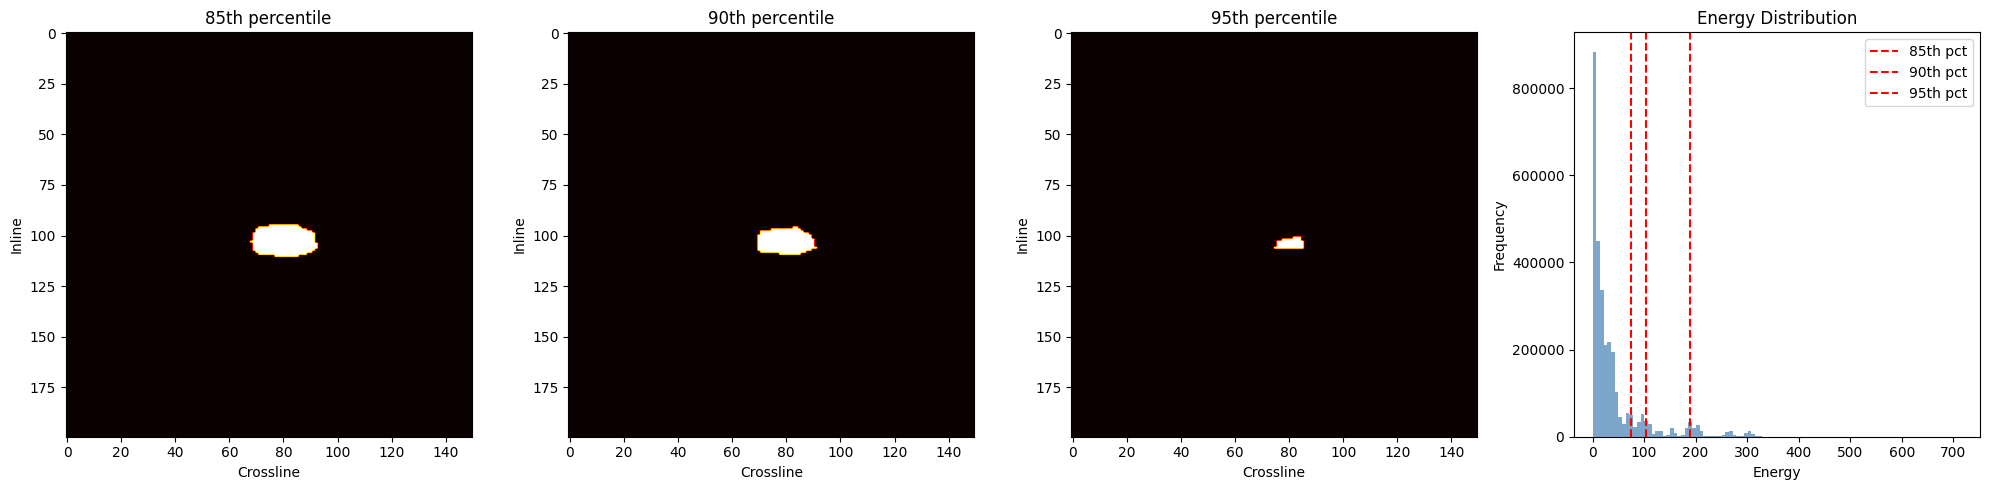


Anomaly Detection Statistics:
--------------------------------------------------
Threshold 85%:
  Anomalous samples: 450,000
  Percentage: 15.00%
  Volume ratio: 0.1500
Threshold 90%:
  Anomalous samples: 300,000
  Percentage: 10.00%
  Volume ratio: 0.1000
Threshold 95%:
  Anomalous samples: 150,000
  Percentage: 5.00%
  Volume ratio: 0.0500
--------------------------------------------------


In [ ]:
import os
import matplotlib.pyplot as plt
import numpy as np

# ----------------------------------------------------------------------
# Advanced anomaly visualization (standalone)
# ----------------------------------------------------------------------
def advanced_anomaly_analysis(processor):
    """
    Visualize anomalies detected at multiple thresholds and show 
    the global energy distribution. Computes statistics for each threshold.
    """
    thresholds = [85, 90, 95]
    fig, axes = plt.subplots(1, len(thresholds)+1, figsize=(20,5))
    slice_idx = processor.volume.shape[2] // 2
    energy = processor.compute_energy_map()

    # Plot anomaly masks for each threshold
    for i, perc in enumerate(thresholds):
        anomaly_mask, _ = processor.detect_anomalies(threshold_percentile=perc)
        axes[i].imshow(anomaly_mask[:,:,slice_idx], cmap='hot', aspect='auto')
        axes[i].set_title(f'{perc}th percentile')
        axes[i].set_xlabel('Crossline')
        axes[i].set_ylabel('Inline')

    # Plot energy histogram
    axes[-1].hist(energy.flatten(), bins=100, color='steelblue', alpha=0.7)
    axes[-1].set_title('Energy Distribution')
    axes[-1].set_xlabel('Energy')
    axes[-1].set_ylabel('Frequency')

    # Add threshold lines to histogram
    for perc in thresholds:
        cutoff = np.percentile(energy, perc)
        axes[-1].axvline(cutoff, color='red', linestyle='--', label=f'{perc}th pct')
    axes[-1].legend()

    # Layout and save
    plt.tight_layout()
    os.makedirs("./output", exist_ok=True)
    plt.savefig("./output/advanced_anomaly_analysis.png", dpi=300)
    plt.show()

    # Compute and print anomaly statistics
    anomaly_stats = {}
    for thresh in thresholds:
        mask, _ = processor.detect_anomalies(threshold_percentile=thresh)
        anomaly_stats[thresh] = {
            'count': np.sum(mask),
            'percentage': 100*np.sum(mask)/mask.size,
            'volume_ratio': np.sum(mask)/np.prod(mask.shape)
        }

    print("\nAnomaly Detection Statistics:")
    print("-"*50)
    for thresh, stats in anomaly_stats.items():
        print(f"Threshold {thresh}%:")
        print(f"  Anomalous samples: {stats['count']:,}")
        print(f"  Percentage: {stats['percentage']:.2f}%")
        print(f"  Volume ratio: {stats['volume_ratio']:.4f}")
    print("-"*50)

def main():
    processor = SeismicWaveletProcessor(wavelet='db4', mode='symmetric')

    # Only synthetic data for testing
    load_seismic_data(processor)  

    processor.preprocess(normalize=True, denoise=True, sigma=0.5)
    processor.decompose_mallat(level=3)

    return processor


if __name__ == "__main__":
    processor = main()
    advanced_anomaly_analysis(processor)


## 2.6 Advanced Analysis Techniques

### 2.6.1 Multi-Scale Energy Analysis

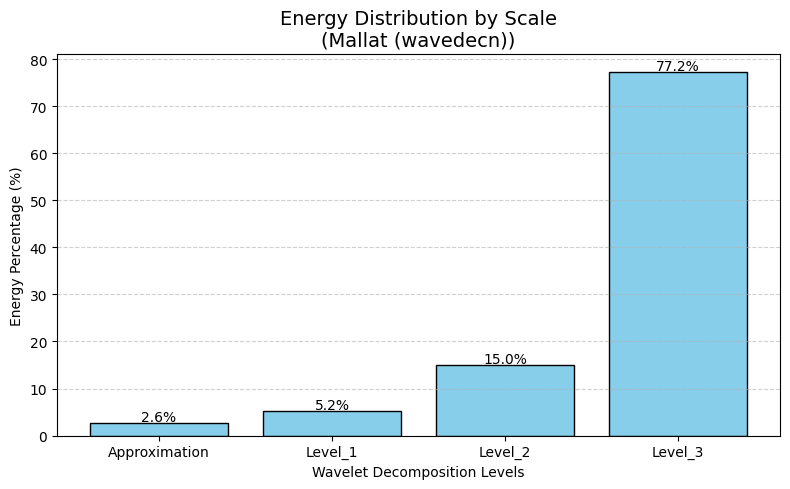


Energy Distribution by Scale:
--------------------------------------------------
Decomposition type: Mallat (wavedecn)

Approximation: 4.30e+03 (2.59%)
Level_1: 8.67e+03 (5.22%)
Level_2: 2.49e+04 (15.02%)
Level_3: 1.28e+05 (77.17%)


In [ ]:
import os
import numpy as np
import pywt
import matplotlib.pyplot as plt

# ----------------------------------------------------------------------
# Multi-scale energy analysis
# ----------------------------------------------------------------------
def multi_scale_energy_analysis(coeffs, save_path="./output/energy_distribution.png"):
    """Analyze energy distribution across scales and plot results"""

    energy_by_scale = {}

    # Case 1: Fully separable coeffs (fswavedecn or new API object)
    if hasattr(coeffs, "coeffs"):  # FswavedecnResult-like object
        decomposition_type = "Fully Separable (fswavedecn)"
        for i, level in enumerate(coeffs.coeffs):
            if i == 0:  # Approximation
                energy_by_scale['Approximation'] = np.sum(level**2)
            else:
                level_energy = sum(np.sum(subband**2) for subband in level.values())
                energy_by_scale[f'Level_{i}'] = level_energy

    # Case 2: Mallat coeffs (classic wavedecn returns list)
    else:
        decomposition_type = "Mallat (wavedecn)"
        energy_by_scale['Approximation'] = np.sum(coeffs[0]**2)
        for i, level in enumerate(coeffs[1:], 1):
            level_energy = sum(np.sum(subband**2) for subband in level.values())
            energy_by_scale[f'Level_{i}'] = level_energy

    # Normalize energies
    total_energy = sum(energy_by_scale.values())
    energy_percentages = {k: 100*v/total_energy for k, v in energy_by_scale.items()}

    # -------------------------------
    # Plot bar chart of energy ratios
    # -------------------------------
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    labels = list(energy_percentages.keys())
    values = list(energy_percentages.values())

    plt.figure(figsize=(8, 5))
    plt.bar(labels, values, color='skyblue', edgecolor='black')
    plt.title(f"Energy Distribution by Scale\n({decomposition_type})", fontsize=14)
    plt.ylabel("Energy Percentage (%)")
    plt.xlabel("Wavelet Decomposition Levels")
    plt.grid(axis='y', linestyle='--', alpha=0.6)

    for i, v in enumerate(values):
        plt.text(i, v + 0.5, f"{v:.1f}%", ha='center', fontsize=10)

    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.show()

    return decomposition_type, energy_by_scale, energy_percentages


# ----------------------------------------------------------------------
# Example main()
# ----------------------------------------------------------------------
def main():
    # Generate synthetic 3D volume
    volume = np.random.randn(64, 64, 32)

    # Perform Mallat 3D wavelet decomposition
    coeffs = pywt.wavedecn(volume, wavelet="db2", mode="symmetric", level=3)

    # Run energy analysis
    decomposition_type, energy_by_scale, energy_percentages = multi_scale_energy_analysis(coeffs)

    print("\nEnergy Distribution by Scale:")
    print("-"*50)
    print(f"Decomposition type: {decomposition_type}\n")
    for k, v in energy_by_scale.items():
        print(f"{k}: {v:.2e} ({energy_percentages[k]:.2f}%)")

    return decomposition_type, energy_by_scale, energy_percentages


if __name__ == "__main__":
    main()


### 2.6.2 Directional Coherence Analysis

Starting seismic directional coherence analysis...


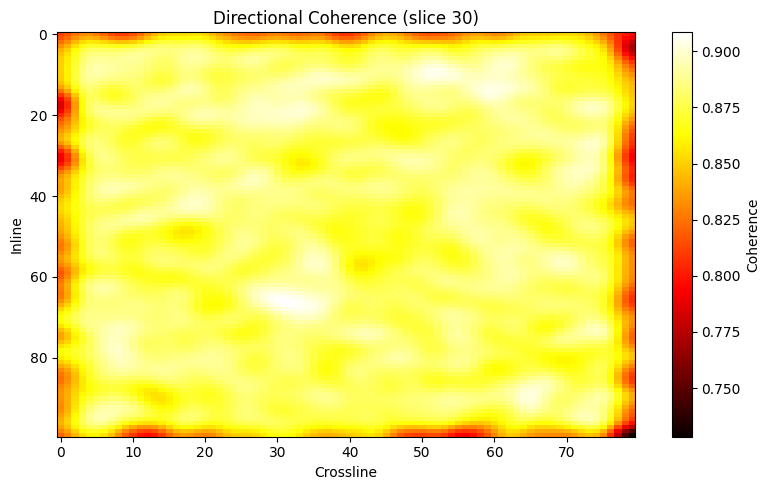

Analysis complete.


In [ ]:
import numpy as np
from scipy import ndimage
import matplotlib.pyplot as plt


def directional_coherence_analysis(volume):
    """
    Compute directional coherence attributes for a 3D seismic volume.

    Returns:
        coherence: 3D array of coherence values (higher = more continuous structure)
        tensors: dict of smoothed structure tensor components
    """
    # Compute gradients along each axis
    grad_x, grad_y, grad_z = np.gradient(volume)

    # Structure tensor components
    Jxx = grad_x * grad_x
    Jyy = grad_y * grad_y
    Jzz = grad_z * grad_z
    Jxy = grad_x * grad_y
    Jxz = grad_x * grad_z
    Jyz = grad_y * grad_z

    # Smooth tensor components (Gaussian filter)
    sigma = 2.0
    Jxx = ndimage.gaussian_filter(Jxx, sigma)
    Jyy = ndimage.gaussian_filter(Jyy, sigma)
    Jzz = ndimage.gaussian_filter(Jzz, sigma)
    Jxy = ndimage.gaussian_filter(Jxy, sigma)
    Jxz = ndimage.gaussian_filter(Jxz, sigma)
    Jyz = ndimage.gaussian_filter(Jyz, sigma)

    # Stack tensor for eigenvalue analysis
    # Shape: (nx, ny, nz, 3, 3)
    tensor = np.empty(volume.shape + (3, 3))
    tensor[..., 0, 0] = Jxx
    tensor[..., 1, 1] = Jyy
    tensor[..., 2, 2] = Jzz
    tensor[..., 0, 1] = tensor[..., 1, 0] = Jxy
    tensor[..., 0, 2] = tensor[..., 2, 0] = Jxz
    tensor[..., 1, 2] = tensor[..., 2, 1] = Jyz

    # Compute largest eigenvalue (structure continuity)
    eigvals = np.linalg.eigvalsh(tensor)
    # Coherence: ratio of largest to sum of eigenvalues (normalized continuity)
    coherence = eigvals[..., -1] / (np.sum(eigvals, axis=-1) + 1e-10)

    tensors = {
        'Jxx': Jxx, 'Jyy': Jyy, 'Jzz': Jzz,
        'Jxy': Jxy, 'Jxz': Jxz, 'Jyz': Jyz
    }
    return coherence, tensors

def main():
    """
    Main function to run seismic directional coherence analysis and visualization.
    """
    print("Starting seismic directional coherence analysis...")

    # Example: create synthetic seismic volume
    nx, ny, nz = 100, 80, 60
    volume = np.zeros((nx, ny, nz))
    for i in range(nz):
        volume[:, :, i] = np.sin(2 * np.pi * i / 20) + 0.1 * np.random.randn(nx, ny)

    # Run coherence analysis
    coherence, tensors = directional_coherence_analysis(volume)

    # Visualize a slice of coherence
    slice_idx = nz // 2
    plt.figure(figsize=(8, 5))
    plt.imshow(coherence[:, :, slice_idx], cmap='hot', aspect='auto')
    plt.title(f'Directional Coherence (slice {slice_idx})')
    plt.xlabel('Crossline')
    plt.ylabel('Inline')
    plt.colorbar(label='Coherence')
    plt.tight_layout()
    plt.savefig("./output/directional_coherence_map.png")
    plt.show()

    print("Analysis complete.")

if __name__ == "__main__":
    main()

## 2.7 Performance Optimization and Best Practices

### 2.7.1 Memory Management for Large Datasets

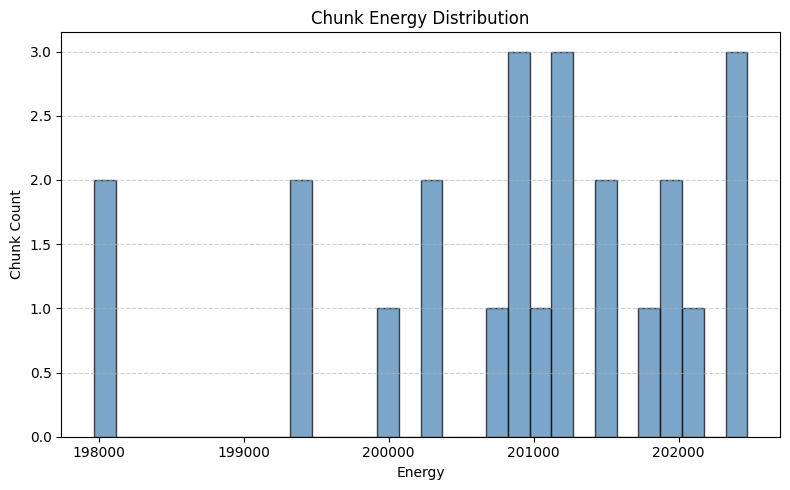

Chunk energy distribution plot saved to ./output\16.5_chunk_energy_distribution.png
Processed 24 chunks.
First chunk info: {'position': (0, 0, 0), 'shape': (50, 50, 50), 'energy': np.float64(200839.84756130198), 'coeffs': [array([[[-4.49743223e-02,  1.07947576e+00, -1.05217550e+00, ...,
         -1.14020731e-02, -6.99368089e-01,  3.28408237e-01],
        [ 3.26462600e-03,  1.30258193e+00, -6.80028749e-01, ...,
         -6.00255002e-01,  1.92441144e+00, -6.49421072e-01],
        [-1.04151414e-01,  7.80547590e-01, -1.24588164e+00, ...,
          3.70902154e-01, -2.31629382e+00,  5.00354325e-01],
        ...,
        [-2.93413340e-02,  1.08696630e+00, -5.04061235e-01, ...,
          4.65467061e-01,  3.70153312e-01, -1.02176169e+00],
        [ 1.08657946e+00,  2.21886858e+00,  4.04741869e-01, ...,
         -1.01922942e+00,  2.24036669e+00,  1.18730378e-01],
        [ 2.03722420e+00,  2.23625038e-01,  4.34360908e+00, ...,
          1.14214513e+00,  4.51578780e-01, -2.51556867e+00]],

      

In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt

def process_large_volume_chunked(volume_path, chunk_size=(100, 100, 100), wavelet='db4', level=2, plot_stats=True, output_dir="./output"):
    """
    Process large volumes using chunking strategy and visualize chunk statistics.

    Args:
        volume_path (str): Path to .npy file containing the volume.
        chunk_size (tuple): Size of each chunk (nx, ny, nz).
        wavelet (str): Wavelet type for decomposition.
        level (int): Decomposition level.
        plot_stats (bool): If True, plot energy distribution across chunks.
        output_dir (str): Directory to save plots.

    Returns:
        results (list): List of dicts with chunk info and coefficients.
    """
    import os
    os.makedirs(output_dir, exist_ok=True)

    # Memory-mapped array for large datasets
    volume = np.load(volume_path, mmap_mode='r')
    nx, ny, nz = volume.shape

    results = []
    energies = []

    for i in range(0, nx, chunk_size[0]):
        for j in range(0, ny, chunk_size[1]):
            for k in range(0, nz, chunk_size[2]):
                # Define chunk boundaries
                i_end = min(i + chunk_size[0], nx)
                j_end = min(j + chunk_size[1], ny)
                k_end = min(k + chunk_size[2], nz)

                # Extract chunk
                chunk = volume[i:i_end, j:j_end, k:k_end].copy()

                # Process chunk
                coeffs = pywt.wavedecn(chunk, wavelet=wavelet, level=level)
                # Compute energy (sum of squares of all coefficients)
                chunk_energy = 0
                chunk_energy += np.sum(coeffs[0] ** 2)
                for detail in coeffs[1:]:
                    for arr in detail.values():
                        chunk_energy += np.sum(arr ** 2)
                energies.append(chunk_energy)

                # Store results
                results.append({
                    'position': (i, j, k),
                    'shape': chunk.shape,
                    'energy': chunk_energy,
                    'coeffs': coeffs
                })

    # Plot energy distribution across chunks
    if plot_stats and energies:
        plt.figure(figsize=(8, 5))
        plt.hist(energies, bins=30, color='steelblue', edgecolor='black', alpha=0.7)
        plt.title("Chunk Energy Distribution")
        plt.xlabel("Energy")
        plt.ylabel("Chunk Count")
        plt.grid(axis='y', linestyle='--', alpha=0.6)
        plt.tight_layout()
        plot_path = os.path.join(output_dir, "chunk_energy_distribution.png")
        plt.savefig(plot_path, dpi=300)
        
        plt.show()
        print(f"Chunk energy distribution plot saved to {plot_path}")

    return results

# Example main function
def main():
    # For demonstration, create a synthetic volume and save to disk
    nx, ny, nz = 200, 150, 100
    volume = np.random.randn(nx, ny, nz)
    volume_path = "./output/synthetic_large_volume.npy"
    np.save(volume_path, volume)

    # Process the volume in chunks and plot statistics
    results = process_large_volume_chunked(
        volume_path,
        chunk_size=(50, 50, 50),
        wavelet='db4',
        level=2,
        plot_stats=True,
        output_dir="./output"
    )

    # Print summary
    print(f"Processed {len(results)} chunks.")
    print("First chunk info:", results[0])

if __name__ == "__main__":
    main()

### 2.8.2 Quality Metrics


Quality Metrics
----------------------------------------
mse            : 0.0000
rmse           : 0.0000
psnr           : 204.7611
correlation    : 1.0000
snr            : 93.0125
anomaly_ratio  : 0.1000
anomaly_energy : 0.2511
----------------------------------------


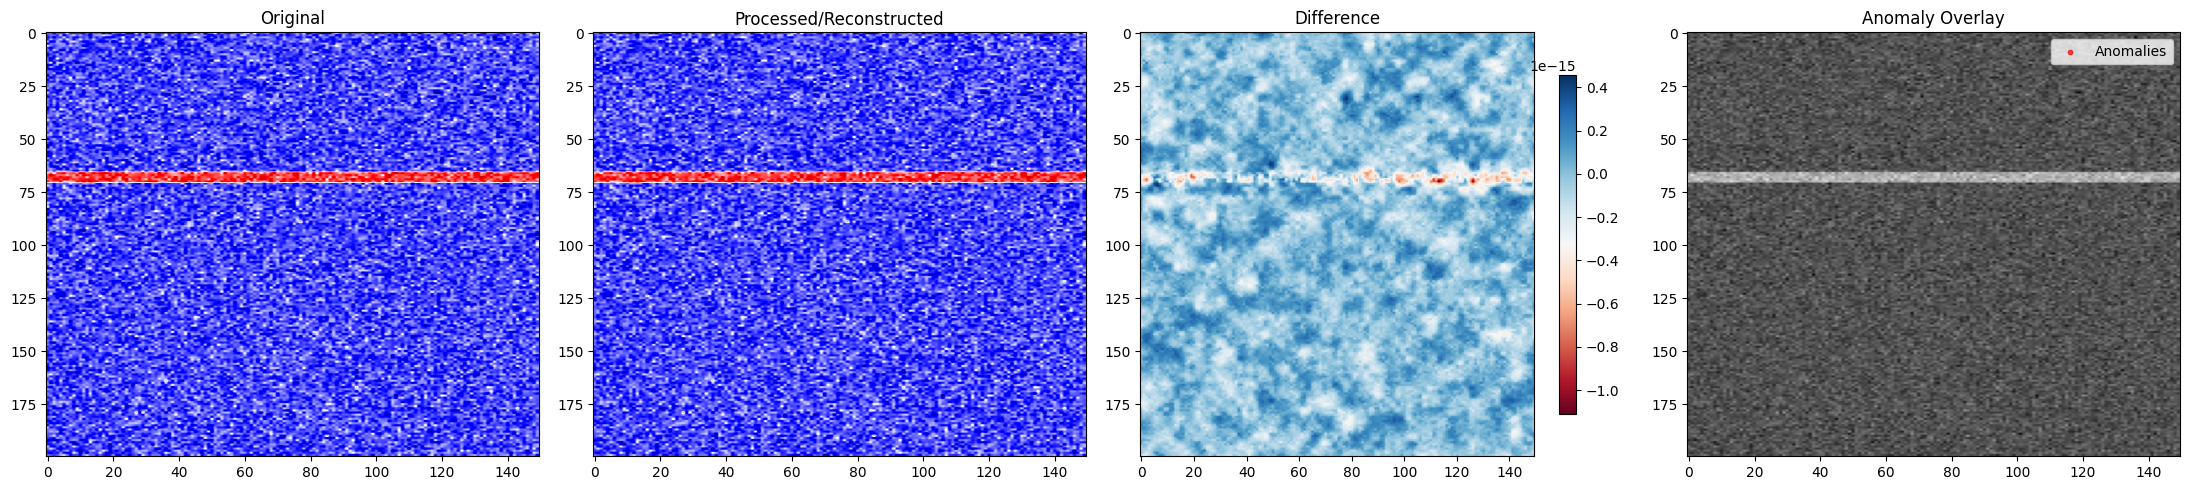

In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt
from scipy import ndimage   # <-- Add this import

def compute_quality_metrics(original, processed, anomaly_mask=None, plot=True):
    """
    Comprehensive quality assessment with optional plots.
    Plots: Original | Processed | Difference | Anomaly Overlay (if mask)
    """
    metrics = {
        'mse': np.mean((original - processed)**2),
        'rmse': np.sqrt(np.mean((original - processed)**2)),
        'psnr': 20 * np.log10(np.max(original) / (np.sqrt(np.mean((original - processed)**2)) + 1e-10)),
        'correlation': np.corrcoef(original.flatten(), processed.flatten())[0, 1],
        'snr': 10 * np.log10(np.mean(original**2) / (np.mean((original - processed)**2) + 1e-10))
    }

    if anomaly_mask is not None:
        metrics['anomaly_ratio'] = np.sum(anomaly_mask) / anomaly_mask.size
        metrics['anomaly_energy'] = np.sum(original[anomaly_mask]**2) / (np.sum(original**2) + 1e-10)

    print("\nQuality Metrics")
    print("-" * 40)
    for k, v in metrics.items():
        print(f"{k:15}: {v:.4f}")
    print("-" * 40)

    if plot:
        slice_idx = original.shape[2] // 2
        fig, axes = plt.subplots(1, 4, figsize=(22, 5))
        # Original
        axes[0].imshow(original[:, :, slice_idx], cmap='seismic', aspect='auto')
        axes[0].set_title('Original')
        # Processed/Reconstructed
        axes[1].imshow(processed[:, :, slice_idx], cmap='seismic', aspect='auto')
        axes[1].set_title('Processed/Reconstructed')
        # Difference
        diff = original - processed
        im = axes[2].imshow(diff[:, :, slice_idx], cmap='RdBu', aspect='auto')
        axes[2].set_title('Difference')
        plt.colorbar(im, ax=axes[2], shrink=0.8)
        # Anomaly Overlay
        if anomaly_mask is not None:
            axes[3].imshow(original[:, :, slice_idx], cmap='gray', aspect='auto')
            y_idx, x_idx = np.where(anomaly_mask[:, :, slice_idx])
            axes[3].scatter(x_idx, y_idx, c='red', s=10, label='Anomalies', alpha=0.7)
            axes[3].set_title('Anomaly Overlay')
            axes[3].legend()
        else:
            axes[3].axis('off')
        plt.tight_layout()
        plt.savefig("./output/quality_metrics.png", dpi=300)
        plt.show()

    return metrics

def main():
    # Synthetic demonstration
    nx, ny, nz = 200, 150, 100
    np.random.seed(42)
    original = np.zeros((nx, ny, nz))
    for i in range(nz):
        layer_amp = np.sin(2 * np.pi * i / 20) * np.exp(-i / 80)
        original[:, :, i] = layer_amp
    fault_x = nx // 3
    original[fault_x:fault_x + 5, :, :] += 0.5
    original += 0.1 * np.random.randn(nx, ny, nz)

    # Wavelet decomposition and reconstruction
    coeffs = pywt.wavedecn(original, wavelet='db4', level=3, mode='symmetric')
    reconstructed = pywt.waverecn(coeffs, wavelet='db4', mode='symmetric')

    # Simple anomaly mask (top 10% energy)
    energy_map = np.zeros_like(original)
    for detail in coeffs[1:]:
        for arr in detail.values():
            resized = arr
            if arr.shape != original.shape:
                zoom_factors = [s1 / s2 for s1, s2 in zip(original.shape, arr.shape)]
                resized = ndimage.zoom(arr, zoom_factors, order=1)
            energy_map += resized ** 2
    threshold = np.percentile(energy_map, 90)
    anomaly_mask = energy_map > threshold

    # Compute and plot metrics
    compute_quality_metrics(original, reconstructed, anomaly_mask, plot=True)

if __name__ == "__main__":
    main()

## 2.9 Extensions and Advanced Applications

### 2.9.1 Climate Data Processing

===== Climate Data Summary =====
Raw Temperature: mean=0.505, std=0.287, min=0.000, max=1.000
Detrended Temperature: mean=-0.000, std=0.286, min=-0.576, max=0.556
Wavelet Decomposition Levels: 3
  Level 1 detail energy: 37.536
  Level 2 detail energy: 128.754
  Level 3 detail energy: 711.202
Total Detail Energy: 877.492


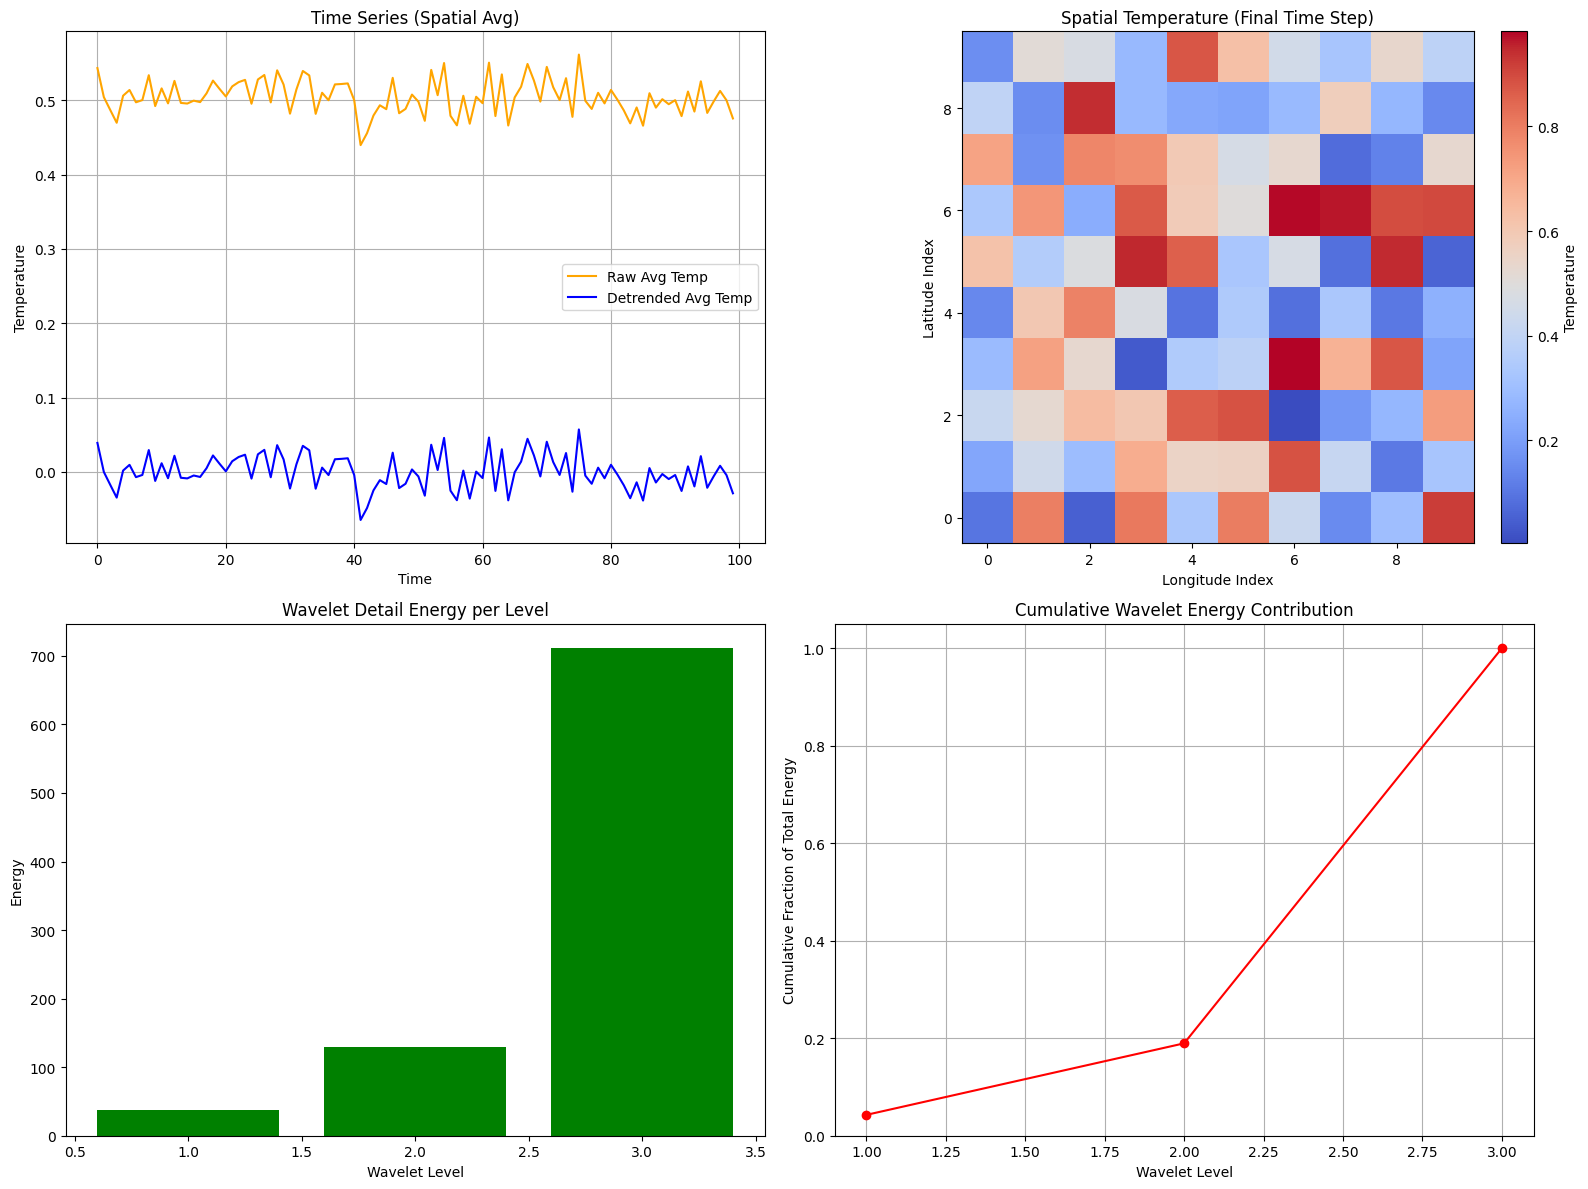

In [ ]:
import numpy as np
from scipy import signal
import pywt
import matplotlib.pyplot as plt

def process_climate_data(temperature_grid, wavelet='db6', level=3, detrend=True, climatology=None, plot=True):
    """
    Process 3D climate data (latitude, longitude, time) for analysis of extreme events
    and provide visualizations and meaningful summary statistics.

    Parameters
    ----------
    temperature_grid : ndarray
        3D NumPy array of shape (lat, lon, time) containing temperature data.
    wavelet : str, optional
        Wavelet type for decomposition (e.g., 'db6', 'coif5'). Default is 'db6'.
    level : int, optional
        Decomposition level for wavelet transform. Default is 3.
    detrend : bool, optional
        If True, remove seasonal trends before wavelet decomposition. Default is True.
    climatology : ndarray, optional
        3D array compatible with temperature_grid for detrending.
    plot : bool, optional
        If True, generate time series, spatial, wavelet energy, and cumulative energy plots. Default is True.

    Returns
    -------
    coeffs : list
        Wavelet decomposition coefficients from pywt.wavedecn.
    detail_energy : float
        Sum of squared detail coefficients, representing energy of extreme events.
    """
    # Input validation
    if not isinstance(temperature_grid, np.ndarray) or temperature_grid.ndim != 3:
        raise ValueError("temperature_grid must be a 3D NumPy array (lat, lon, time)")
    if np.any(np.isnan(temperature_grid)):
        raise ValueError("temperature_grid contains NaN values")
    if not isinstance(level, int) or level <= 0:
        raise ValueError("level must be a positive integer")
    if wavelet not in pywt.wavelist():
        raise ValueError(f"Invalid wavelet type. Choose from {pywt.wavelist()}")

    temperature_grid = temperature_grid.astype(np.float64)

    # Detrend
    if detrend:
        if climatology is not None:
            if not (climatology.ndim == 3 and 
                    climatology.shape[0] == temperature_grid.shape[0] and 
                    climatology.shape[1] == temperature_grid.shape[1]):
                raise ValueError("climatology must have compatible lat/lon dimensions with temperature_grid")
            detrended = temperature_grid - climatology
        else:
            detrended = signal.detrend(temperature_grid, axis=2, type='linear')
    else:
        detrended = temperature_grid

    # Wavelet decomposition
    coeffs = pywt.wavedecn(detrended, wavelet=wavelet, level=level, mode='periodization')

    # Detail energy per level
    detail_energy = 0.0
    level_energies = []
    for detail in coeffs[1:]:
        if isinstance(detail, dict):
            energy = sum(np.sum(c**2) for c in detail.values())
        else:
            energy = np.sum(detail**2)
        level_energies.append(energy)
        detail_energy += energy

    # Meaningful printed results
    avg_raw = np.mean(temperature_grid)
    avg_detrended = np.mean(detrended)
    std_raw = np.std(temperature_grid)
    std_detrended = np.std(detrended)
    max_raw = np.max(temperature_grid)
    min_raw = np.min(temperature_grid)
    max_detrended = np.max(detrended)
    min_detrended = np.min(detrended)

    print("===== Climate Data Summary =====")
    print(f"Raw Temperature: mean={avg_raw:.3f}, std={std_raw:.3f}, min={min_raw:.3f}, max={max_raw:.3f}")
    print(f"Detrended Temperature: mean={avg_detrended:.3f}, std={std_detrended:.3f}, min={min_detrended:.3f}, max={max_detrended:.3f}")
    print(f"Wavelet Decomposition Levels: {level}")
    for i, e in enumerate(level_energies, start=1):
        print(f"  Level {i} detail energy: {e:.3f}")
    print(f"Total Detail Energy: {detail_energy:.3f}")
    print("================================")

    # Plotting
    if plot:
        fig, axes = plt.subplots(2, 2, figsize=(16, 12))
        axes = axes.flatten()

        # 1. Time series plot (average over spatial grid)
        avg_raw_time = np.mean(temperature_grid, axis=(0,1))
        avg_detrended_time = np.mean(detrended, axis=(0,1))
        axes[0].plot(avg_raw_time, label='Raw Avg Temp', color='orange')
        axes[0].plot(avg_detrended_time, label='Detrended Avg Temp', color='blue')
        axes[0].set_title('Time Series (Spatial Avg)')
        axes[0].set_xlabel('Time')
        axes[0].set_ylabel('Temperature')
        axes[0].legend()
        axes[0].grid(True)

        # 2. Spatial heatmap at final time step
        final_temp = temperature_grid[:, :, -1]
        im = axes[1].imshow(final_temp, cmap='coolwarm', origin='lower')
        axes[1].set_title('Spatial Temperature (Final Time Step)')
        axes[1].set_xlabel('Longitude Index')
        axes[1].set_ylabel('Latitude Index')
        fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04, label='Temperature')

        # 3. Wavelet energy per level
        axes[2].bar(range(1, level+1), level_energies, color='green')
        axes[2].set_title('Wavelet Detail Energy per Level')
        axes[2].set_xlabel('Wavelet Level')
        axes[2].set_ylabel('Energy')

        # 4. Cumulative wavelet energy contribution
        cumulative_energy = np.cumsum(level_energies) / detail_energy
        axes[3].plot(range(1, level+1), cumulative_energy, marker='o', color='red')
        axes[3].set_title('Cumulative Wavelet Energy Contribution')
        axes[3].set_xlabel('Wavelet Level')
        axes[3].set_ylabel('Cumulative Fraction of Total Energy')
        axes[3].set_ylim(0, 1.05)
        axes[3].grid(True)

        plt.tight_layout()
        plt.savefig("./output/climate_data_analysis.png", dpi=300)
        plt.show()

    return coeffs, detail_energy


# Example usage
temperature_grid = np.random.rand(10, 10, 100)
climatology = np.mean(temperature_grid, axis=2, keepdims=True)
coeffs, energy = process_climate_data(temperature_grid, wavelet='coif5', level=3, climatology=climatology)


### 2.9.2 Medical Imaging Applications

Dataset already present – skipping download.
Selected file: ./data\Task01_BrainTumour\imagesTr\BRATS_001.nii.gz
Loaded MRI shape: (240, 240, 155, 4)


c:\Users\shouk\AppData\Local\Programs\Python\Python313\Lib\site-packages\pywt\_multilevel.py:43: UserWarning: Level value of 3 is too high: all coefficients will experience boundary effects.
  warnings.warn(


===== MRI Volume Summary =====
Volume shape: (240, 240, 155, 4)
Intensity - mean: 104.089, std: 254.886, min: 0.000, max: 2239.000
Wavelet energy map - mean: 2.452, std: 23.866, max: 13191.801


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..2238.0].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [6.367452663708619e-23..68.2113017731833].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..2238.0].


Detected anomalies: 1517484 voxels (4.25% of total volume)


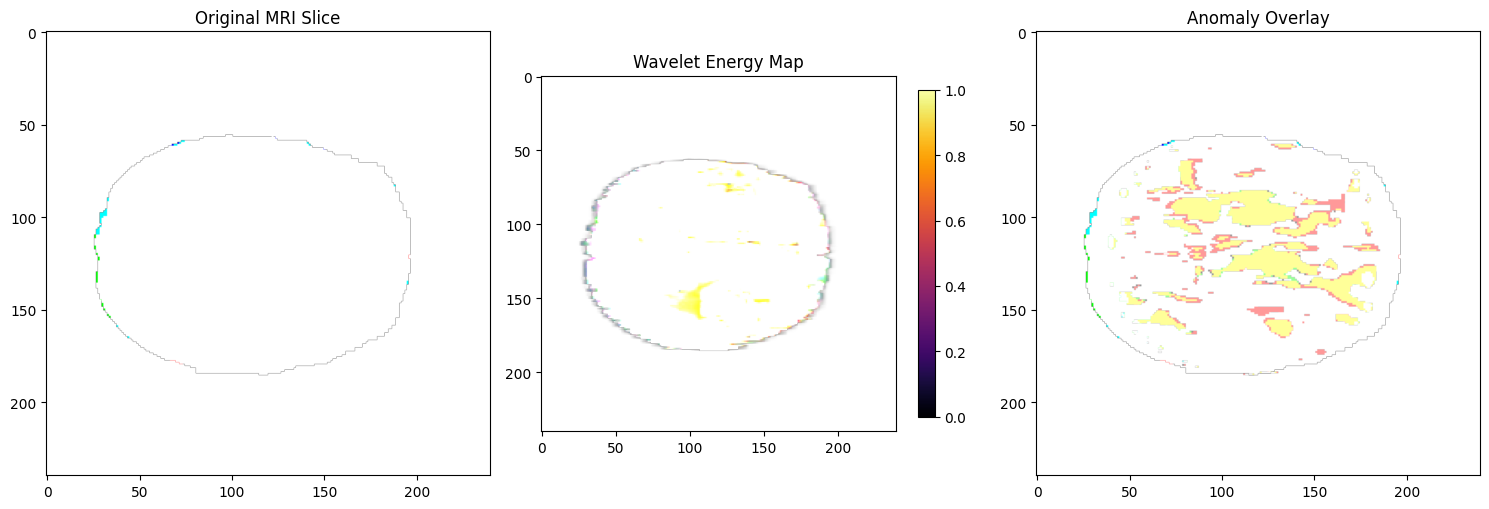

In [ ]:
import os
import numpy as np
import pywt
from scipy import ndimage
import matplotlib.pyplot as plt
import nibabel as nib
from monai.apps import download_and_extract

def slice_wavelet_anomaly(volume, wavelet='bior4.4', threshold_percentile=95):
    anomalies = np.zeros_like(volume, dtype=bool)
    energy_map = np.zeros_like(volume, dtype=float)

    for i in range(volume.shape[2]):  # iterate slices along z-axis
        slice_img = volume[:, :, i]
        slice_norm = (slice_img - np.mean(slice_img)) / (np.std(slice_img) + 1e-8)
        coeffs = pywt.wavedec2(slice_norm, wavelet=wavelet, level=3)
        slice_energy = np.zeros_like(slice_norm)
        for detail in coeffs[1:]:
            for arr in detail:
                zoom_factors = [s1 / s2 for s1, s2 in zip(slice_norm.shape, arr.shape)]
                slice_energy += ndimage.zoom(arr**2, zoom_factors, order=1)
        energy_map[:, :, i] = slice_energy
        thresh = np.percentile(slice_energy, threshold_percentile)
        anomalies[:, :, i] = slice_energy > thresh

    return anomalies, energy_map

def main():
    # -----------------------------
    # 1. Dataset setup
    # -----------------------------
    url = "https://msd-for-monai.s3-us-west-2.amazonaws.com/Task01_BrainTumour.tar"
    dataset_dir = "./data"
    tar_path = os.path.join(dataset_dir, "Task01_BrainTumour.tar")
    extracted_dir = os.path.join(dataset_dir, "Task01_BrainTumour")

    os.makedirs(dataset_dir, exist_ok=True)

    if not os.path.exists(extracted_dir):
        print("Downloading and extracting dataset...")
        try:
            download_and_extract(url, dataset_dir)
        except Exception as e:
            print(f"Error downloading/extracting dataset: {e}")
            return
    else:
        print("Dataset already present – skipping download.")

    images_tr_dir = os.path.join(extracted_dir, "imagesTr")
    if not os.path.exists(images_tr_dir):
        print(f"Error: Directory {images_tr_dir} does not exist.")
        return

    try:
        valid_files = [f for f in os.listdir(images_tr_dir) if f.endswith(".nii.gz") and not f.startswith("._")]
        if not valid_files:
            print(f"Error: No valid .nii.gz files found in {images_tr_dir}.")
            return
        sample_file = os.path.join(images_tr_dir, valid_files[0])
        print(f"Selected file: {sample_file}")
    except Exception as e:
        print(f"Error accessing files in {images_tr_dir}: {e}")
        return

    # -----------------------------
    # 2. Load 3D MRI volume
    # -----------------------------
    try:
        img = nib.load(sample_file)
        mri_volume = img.get_fdata()
        print("Loaded MRI shape:", mri_volume.shape)
    except Exception as e:
        print(f"Error loading MRI file {sample_file}: {e}")
        return

    # -----------------------------
    # 3. Slice-by-slice anomaly detection
    # -----------------------------
    anomalies, energy_map = slice_wavelet_anomaly(mri_volume)

    # -----------------------------
    # 4. Meaningful printed results
    # -----------------------------
    print("===== MRI Volume Summary =====")
    print(f"Volume shape: {mri_volume.shape}")
    print(f"Intensity - mean: {np.mean(mri_volume):.3f}, std: {np.std(mri_volume):.3f}, min: {np.min(mri_volume):.3f}, max: {np.max(mri_volume):.3f}")
    print(f"Wavelet energy map - mean: {np.mean(energy_map):.3f}, std: {np.std(energy_map):.3f}, max: {np.max(energy_map):.3f}")
    num_anomalies = np.sum(anomalies)
    total_voxels = mri_volume.size
    print(f"Detected anomalies: {num_anomalies} voxels ({100*num_anomalies/total_voxels:.2f}% of total volume)")
    print("================================")

    # -----------------------------
    # 5. Visualize middle slice
    # -----------------------------
    slice_idx = mri_volume.shape[2] // 2
    os.makedirs("./output", exist_ok=True)
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(mri_volume[:, :, slice_idx], cmap='gray')
    axes[0].set_title("Original MRI Slice")

    im1 = axes[1].imshow(energy_map[:, :, slice_idx], cmap='inferno')
    axes[1].set_title("Wavelet Energy Map")
    plt.colorbar(im1, ax=axes[1], shrink=0.7)

    overlay = np.zeros_like(mri_volume[:, :, slice_idx], dtype=float)
    overlay[anomalies[:, :, slice_idx]] = 1
    axes[2].imshow(mri_volume[:, :, slice_idx], cmap='gray')
    axes[2].imshow(overlay, cmap='Reds', alpha=0.4)
    axes[2].set_title("Anomaly Overlay")

    plt.tight_layout()
    plt.savefig("./output/mri_anomaly_detection.png", dpi=300)
    plt.show()

if __name__ == "__main__":
    main()
